# Decoding A against 8 perturbations, at 8 orientations — fork of [`decoding.ipynb`](decoding.ipynb)

Exploratory: the figures here are **shown, never saved**.

The same decoder, populations and recorded trials as `decoding.ipynb`, with the stimuli
parameterised and repeated around the ring. At orientation $m$ and inter-object distance $D$,
the reference is

$$\text{A} = (\theta_0, \theta_1) = (m + D/2,\ m - D/2),$$

and it is compared with 8 perturbations of it, each a vector of length $\delta$ in direction
$\psi$ of $(\theta_0, \theta_1)$ space:

$$\text{A} + \delta\,(\cos\psi,\ \sin\psi), \qquad \psi = 0°, 45°, \dots, 315°.$$

$\psi = 45°/225°$ rotates the pair (CCW/CW) with the separation fixed — the relational
neuron's sensitive direction; $\psi = 135°/315°$ shrinks/grows the separation with the midpoint
fixed — the direction a relational neuron is blind to. $\psi = 0/90/180/270$ move one object
only. `decoding.ipynb`'s B and C are $\psi = 225°$ and $135°$ at $m = 0$, $D = 180$,
$\delta = 15\sqrt2$; §1 checks that.

The neurons are re-selected **per orientation**: a neuron needs `DECODE_SPLITS` recorded trials
within `REAL_TOL_DEG` of every stimulus to be cross-validated, so which neurons are eligible
depends on where the stimuli are (`decode_lib.enough_trials_mask`). Within that, the selection
rule is unchanged — the N best-fit neurons of each model, per animal.


In [34]:
# ── CONFIG ───────────────────────────────────────────────────────────────────
# ── The stimulus pattern ─────────────────────────────────────────────────────
SEPARATION_DEG = 180.0   # D: angular distance between A's two objects
PERTURB_DEG = 30.0       # delta: LENGTH of the perturbation vector (dtheta_0, dtheta_1)
# Directions psi of the perturbation in (theta_0, theta_1) space: A + delta*(cos psi, sin psi).
# 45/225 = the pair rotates (CCW/CW), separation fixed; 135/315 = separation shrinks/grows,
# midpoint fixed; 0/180 and 90/270 move one object only.
PERTURB_DIRS_DEG = [0, 45, 90, 135, 180, 225, 270, 315]
ORIENTATIONS_DEG = [0, 45, 90, 135, 180, 225, 270, 315]   # m: A = (m + D/2, m - D/2)

# ── What to measure ─────────────────────────────────────────────────────────
# 'decoding' — held-out accuracy of a linear classifier, A vs each perturbation (as in
#              decoding.ipynb).
# 'fisher'   — linear Fisher information along each perturbation direction, from the same
#              recorded trials: d'^2 / delta^2, in rad^-2 (see §2).
METRIC = 'fisher'
# How 'fisher' estimates each stimulus's mean rate (and variance), per neuron:
# 'window' — plain mean over the trials whose objects are both within REAL_TOL_DEG of the
#            stimulus (the decoder's trial pools).
# 'kernel' — weighted mean over ALL of the neuron's 2-object trials, each weighted by a Gaussian
#            of its distance to the stimulus in (theta_0, theta_1):
#            w = exp(-d^2 / 2 KERNEL_SIGMA_DEG^2), d^2 = dtheta_0^2 + dtheta_1^2 under whichever
#            object pairing is closer. See the schematic in §1.
FISHER_MEAN = 'kernel'
KERNEL_SIGMA_DEG = 20.0
FISHER_N_BOOT = 200      # bootstrap resamples of trials, for the Fisher error bars
FISHER_SEED = 0

# ── Populations, trials, decoder — as in decoding.ipynb ─────────────────────
N_NEURONS = 20           # per animal AND per side
SELECT_SEED = 0
REAL_TOL_DEG = 20.0      # per-object eligibility radius of a recorded trial
REAL_EXCLUSIVE = True    # each trial goes to the nearer stimulus, so the classes are disjoint
REAL_N_TEST = 100
DECODE_N_TRIALS = 200
DECODE_SPLITS = 5
DECODE_SEED = 0
DECODE_C = 1.0

# ── Figure (shown only) ──────────────────────────────────────────────────────
N_COLS = 1               # orientation panels per row (1 = one tall column)
PANEL_SIZE = (7.4, 2.6)  # inches per panel (width, height)
DISC_RADIUS, DISC_COLOR = 0.2, '0.6'
ARROWS = False           # red arcs from each A object to where it moved
ARROW_COLOR, ARROW_RADIUS = (1, 0, 0), 0.72
# Each direction carries an inset of its perturbed stimulus with A's objects dashed. The y
# axis runs past the data by INSET_HEADROOM to leave room above the lines; INSET_Y is the
# inset's bottom edge and
# INSET_SIZE its height, both in AXES FRACTIONS (the ring stays round, so a narrow panel can
# make it smaller than this).
INSET_HEADROOM = 1.25    # room above the data for the insets, as a multiple of the data range
INSET_Y = 0.6
INSET_SIZE = 0.4
REAL_COLORS = ('tab:blue', 'tab:orange')       # retinotopic, relational
REAL_LABELS = {'retinotopic': 'Retinotopic', 'relational': 'Relational'}
BAR_YLIM = (0.4, 1.0)   # accuracy range drawn ('decoding'; 'fisher' fits its own range)
LINE_MARKER_SIZE = 4

In [35]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append('..')
sys.path.append('../..')
sys.path.append('../efficient_coding')
import common
import config                       # the shared selection criteria; set_style() re-reads it

import decode_lib as dl
import pool_lib as pool

common.set_style()

# Every orientation re-selects its neurons, and the selection reads each candidate's trials from
# the session caches (`stats_lib.session_unit_trials`, a gzipped CSV per session) to check it has
# enough near every stimulus. Uncached, that re-reads the same sessions at every orientation and
# is most of this notebook's run time; memoised, each session is read once.
import functools
pool.sl.session_unit_trials = functools.lru_cache(maxsize=None)(pool.sl.session_unit_trials)

DECODE_KW = dict(n_trials=DECODE_N_TRIALS, n_test=REAL_N_TEST, exclusive=REAL_EXCLUSIVE,
                 n_splits=DECODE_SPLITS, seed=DECODE_SEED, C=DECODE_C)


def perturbed_stimuli_deg(m, sep=SEPARATION_DEG, delta=PERTURB_DEG, dirs=PERTURB_DIRS_DEG):
    # [A, A + delta*(cos psi, sin psi) for psi in dirs] as (theta_0, theta_1) in degrees, in [0, 360).
    a0, a1 = m + sep / 2.0, m - sep / 2.0
    out = [(a0, a1)] + [(a0 + delta * np.cos(np.radians(p)), a1 + delta * np.sin(np.radians(p)))
                        for p in dirs]
    return [tuple(float(t % 360.0) for t in s) for s in out]


STIM_LABELS = ['A'] + [f'{p:g}°' for p in PERTURB_DIRS_DEG]
PAIRS = [(0, k) for k in range(1, len(STIM_LABELS))]     # A vs each perturbation


def kernel_weights(t0, t1, stim, sigma_rad):
    # Gaussian weight of each trial (t0, t1) for stimulus `stim` = (s0, s1), all radians. The
    # distance is Euclidean in (theta_0, theta_1) with circular differences, under whichever
    # object pairing is closer -- (t0, t1) and (t1, t0) are the same stimulus.
    s0, s1 = stim
    d2 = np.minimum(dl.circ_dist(t0, s0) ** 2 + dl.circ_dist(t1, s1) ** 2,
                    dl.circ_dist(t0, s1) ** 2 + dl.circ_dist(t1, s0) ** 2)
    return np.exp(-0.5 * d2 / sigma_rad ** 2)


def linear_fisher_kernel(unit_trials, stim_a, stim_b, delta_rad, sigma_rad, n_boot=200, seed=0):
    # As `linear_fisher`, but each stimulus's mean is a kernel-weighted mean over ALL trials:
    #   mu_s = sum_t w_s(t) r_t / sum_t w_s(t).
    # The variance is the matching weighted variance (corrected by n_eff = (sum w)^2 / sum w^2),
    # pooled over the two stimuli. The two kernels overlap -- one trial can count towards both
    # means -- so the noise in mu_b - mu_a is sum_t c_t^2 sigma^2 with
    # c_t = w_b(t)/sum w_b - w_a(t)/sum w_a, and that is the bias subtracted:
    #   d'^2 = (mu_b - mu_a)^2 / var  -  sum_t c_t^2.
    rng = np.random.default_rng(seed)

    def dprime2(wa, wb, r):
        # [..., n] on the last axis, so a whole bootstrap is one call.
        sa, sb = wa.sum(-1, keepdims=True), wb.sum(-1, keepdims=True)
        pa, pb = wa / sa, wb / sb                          # normalised weights
        ma, mb = (pa * r).sum(-1), (pb * r).sum(-1)
        na, nb = 1.0 / (pa ** 2).sum(-1), 1.0 / (pb ** 2).sum(-1)     # effective n
        va = (pa * (r - ma[..., None]) ** 2).sum(-1) * na / (na - 1)
        vb = (pb * (r - mb[..., None]) ** 2).sum(-1) * nb / (nb - 1)
        vp = (na * va + nb * vb) / (na + nb)
        return (mb - ma) ** 2 / vp - ((pb - pa) ** 2).sum(-1), np.minimum(na, nb)

    point, boot, n_eff = 0.0, np.zeros(n_boot), []
    for t0, t1, fr in unit_trials:
        r = np.asarray(fr, float)
        wa, wb = kernel_weights(t0, t1, stim_a, sigma_rad), kernel_weights(t0, t1, stim_b, sigma_rad)
        d, ne = dprime2(wa, wb, r)
        point += float(d)
        n_eff.append(float(ne))
        idx = rng.integers(0, len(r), (n_boot, len(r)))
        boot += dprime2(wa[idx], wb[idx], r[idx])[0]
    return dict(value=point / delta_rad ** 2, value_sem=boot.std(ddof=1) / delta_rad ** 2,
                n_eff_min=min(n_eff))


def linear_fisher(unit_trials, stim_a, stim_b, delta_rad, tol_deg, exclusive=True,
                  n_boot=200, seed=0):
    # Linear Fisher information along the A -> B direction, from recorded trials.
    #
    # Per unit, d'^2 = (mean_b - mean_a)^2 / pooled variance, less its small-sample bias
    # (var_a/n_a + var_b/n_b in the numerator), summed over units -- the units were recorded
    # in different sessions, so there are no noise correlations to include -- and divided by
    # |delta|^2: the finite-difference version of u'Ju. The bias correction makes it unbiased
    # for a unit with no signal, so it can come out slightly negative. Error bars: SD of the
    # same quantity over bootstrap resamples of each unit's trials.
    idx_a, idx_b = dl.trial_pools(unit_trials, stim_a, stim_b, tol_deg=tol_deg,
                                  exclusive=exclusive)
    rng = np.random.default_rng(seed)

    def dprime2(ra, rb):
        # ra, rb: [..., n] trials on the last axis, so a whole bootstrap is one call.
        na, nb = ra.shape[-1], rb.shape[-1]
        va, vb = ra.var(axis=-1, ddof=1), rb.var(axis=-1, ddof=1)
        vp = ((na - 1) * va + (nb - 1) * vb) / (na + nb - 2)
        num = (rb.mean(axis=-1) - ra.mean(axis=-1)) ** 2 - va / na - vb / nb
        return np.where(vp > 0, num / np.where(vp > 0, vp, 1.0), 0.0)

    point, boot = 0.0, np.zeros(n_boot)
    for (_t0, _t1, fr), ia, ib in zip(unit_trials, idx_a, idx_b):
        fr = np.asarray(fr, float)
        ra, rb = fr[ia], fr[ib]
        if len(ra) < 2 or len(rb) < 2:
            raise ValueError('a unit has fewer than 2 trials near a stimulus; widen tol_deg')
        point += float(dprime2(ra, rb))
        boot += dprime2(ra[rng.integers(0, len(ra), (n_boot, len(ra)))],
                        rb[rng.integers(0, len(rb), (n_boot, len(rb)))])
    return dict(value=point / delta_rad ** 2, value_sem=boot.std(ddof=1) / delta_rad ** 2,
                n_pool_min=int(min(min(map(len, idx_a)), min(map(len, idx_b)))))


METRIC_LABEL = {'decoding': 'Accuracy', 'fisher': r'Fisher info (rad$^{-2}$)'}[METRIC]


def draw_stimulus(ax, stim_deg, ref_deg=None, view=1.35):
    # One ring: the stimulus's two objects as gray discs; with `ref_deg`, dashed circles where
    # A's objects were and (ARROWS) an arc from each to where it moved.
    circ = np.linspace(0, 2 * np.pi, 256)
    ax.plot(np.cos(circ), np.sin(circ), color='0.75', lw=1.0, ls='--', zorder=1)
    ax.plot(0, 0, marker='+', color='k', markersize=8, markeredgewidth=1.3, zorder=2)
    stim = np.radians(stim_deg)
    if ref_deg is not None:
        ref = np.radians(ref_deg)
        for t in ref:
            ax.add_patch(plt.Circle((np.cos(t), np.sin(t)), DISC_RADIUS, facecolor='none',
                                    edgecolor='0.45', lw=1.2, ls=(0, (3, 2)), zorder=3))
        if ARROWS:
            for a, b in zip(ref, stim):
                d = float((b - a + np.pi) % (2 * np.pi) - np.pi)
                if abs(np.degrees(d)) < 0.5:
                    continue
                arc = a + np.linspace(0.0, d, 32)
                ax.plot(ARROW_RADIUS * np.cos(arc), ARROW_RADIUS * np.sin(arc),
                        color=ARROW_COLOR, lw=1.6, solid_capstyle='round', zorder=5)
                ax.annotate('', xy=(ARROW_RADIUS * np.cos(arc[-1]), ARROW_RADIUS * np.sin(arc[-1])),
                            xytext=(ARROW_RADIUS * np.cos(arc[-2]),
                                    ARROW_RADIUS * np.sin(arc[-2])),
                            arrowprops=dict(arrowstyle='-|>', color=ARROW_COLOR, lw=1.6,
                                            mutation_scale=10, shrinkA=0, shrinkB=0),
                            zorder=5)
    for t in stim:
        ax.add_patch(plt.Circle((np.cos(t), np.sin(t)), DISC_RADIUS, facecolor=DISC_COLOR,
                                edgecolor='k', lw=0.8, zorder=4))
    ax.set_xlim(-view, view)
    ax.set_ylim(-view, view)
    ax.set_aspect('equal')
    ax.axis('off')

## 1. The stimuli

A, and A moved by a vector of length δ in each direction ψ of $(\theta_0, \theta_1)$ space. They
are drawn as insets in §3; the printout gives each comparison's displacement for the first
orientation (every orientation is the same pattern, rotated) — |Δ| should be δ throughout, ψ = 45/225
a pure rotation and ψ = 135/315 a pure separation change.

In [36]:
STIMULI_DEG = {m: perturbed_stimuli_deg(m) for m in ORIENTATIONS_DEG}

# decoding.ipynb's B and C are the 225° and 135° perturbations of length 15*sqrt(2).
_chk = perturbed_stimuli_deg(0, 180.0, 15 * np.sqrt(2), [225, 135])
assert np.allclose(_chk, [(90, 270), (75, 255), (75, 285)])

m = ORIENTATIONS_DEG[0]
S = dl.stimulus_array(STIMULI_DEG[m])
print(f'orientation {m}°: A = ({STIMULI_DEG[m][0][0]:.1f}, {STIMULI_DEG[m][0][1]:.1f})')
for a, b in PAIRS:
    print(f'  ψ = {STIM_LABELS[b]:>5}: ({STIMULI_DEG[m][b][0]:6.1f}, {STIMULI_DEG[m][b][1]:6.1f})   '
          + dl.describe_pair(S[a], S[b], ('A', STIM_LABELS[b])).split(': ', 1)[1])

orientation 0°: A = (90.0, 270.0)
  ψ =    0°: ( 120.0,  270.0)   |Δ| = 30.0°, rotation +21.2°, separation change +21.2° (180° → 150° apart)
  ψ =   45°: ( 111.2,  291.2)   |Δ| = 30.0°, rotation +30.0°, separation change +0.0° (180° → 180° apart)
  ψ =   90°: (  90.0,  300.0)   |Δ| = 30.0°, rotation +21.2°, separation change -21.2° (180° → 150° apart)
  ψ =  135°: (  68.8,  291.2)   |Δ| = 30.0°, rotation +0.0°, separation change -30.0° (180° → 138° apart)
  ψ =  180°: (  60.0,  270.0)   |Δ| = 30.0°, rotation -21.2°, separation change -21.2° (180° → 150° apart)
  ψ =  225°: (  68.8,  248.8)   |Δ| = 30.0°, rotation -30.0°, separation change +0.0° (180° → 180° apart)
  ψ =  270°: (  90.0,  240.0)   |Δ| = 30.0°, rotation -21.2°, separation change +21.2° (180° → 150° apart)
  ψ =  315°: ( 111.2,  248.8)   |Δ| = 30.0°, rotation +0.0°, separation change +30.0° (180° → 138° apart)


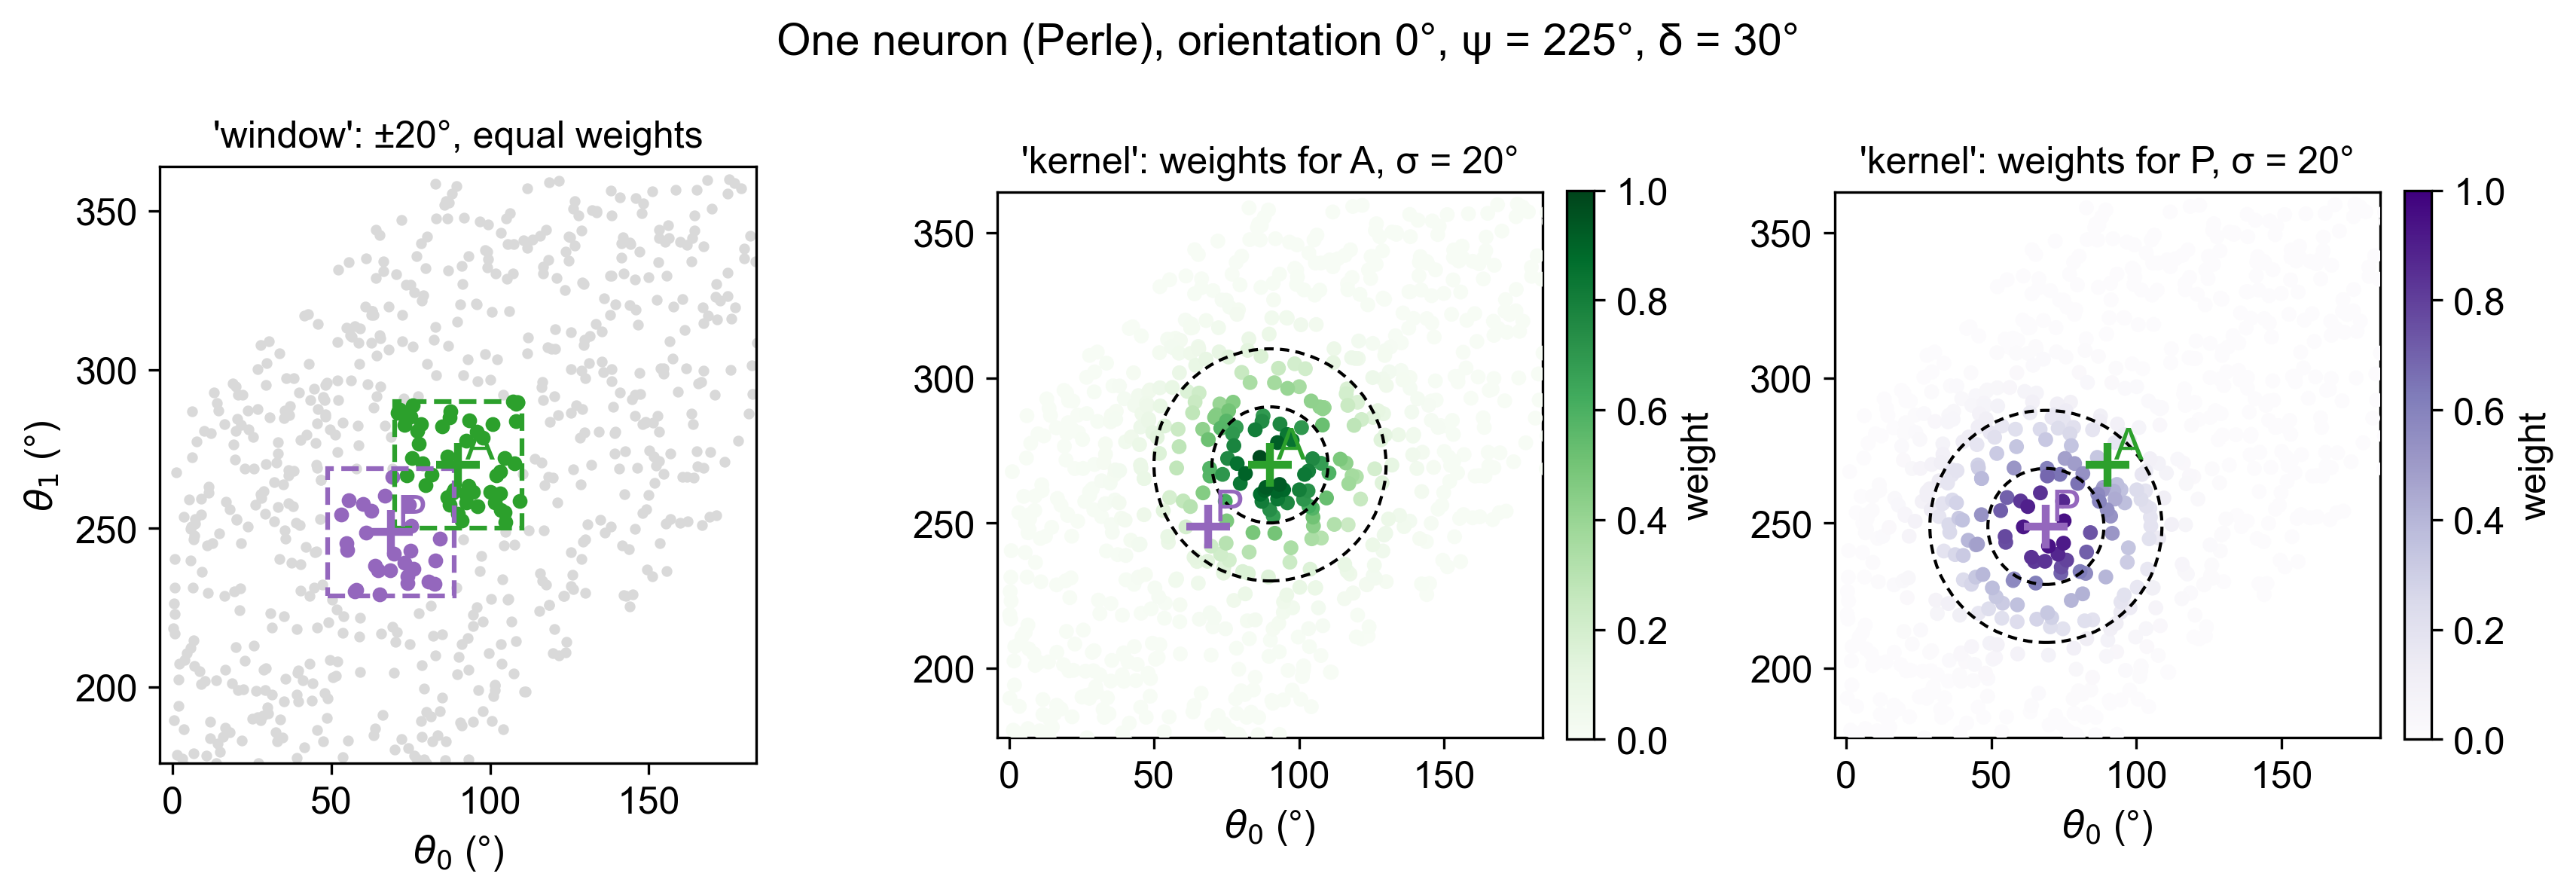

943 trials. window: 50 count for A, 27 for P. kernel: effective n = 123.8 for A (sum of weights 65.1).


In [37]:
# ── Schematic: how a stimulus's mean rate is estimated, for one real neuron ──────────────────
# The (theta_0, theta_1) plane of 2-object stimuli. Every recorded trial is drawn at BOTH
# (t0, t1) and (t1, t0), since the two are the same stimulus; A and the psi = SCHEM_PSI
# perturbation P are the crosses. Left: the 'window' estimate -- a trial counts for a stimulus
# (equal weight) when both objects are within REAL_TOL_DEG, the square box; a trial in both
# boxes goes to the nearer. Middle/right: the 'kernel' estimate -- every trial counts, with
# weight exp(-d^2 / 2 sigma^2) shown as colour; circles mark 1 and 2 sigma.
SCHEM_ORIENTATION, SCHEM_PSI, SCHEM_UNIT = ORIENTATIONS_DEG[0], 225, 0

S_ = dl.stimulus_array(STIMULI_DEG[SCHEM_ORIENTATION])
k_psi = 1 + PERTURB_DIRS_DEG.index(SCHEM_PSI)
_d = dl.select_wedges(dl.SUBJECTS[0], n_per_side=N_NEURONS, seed=SELECT_SEED, verbose=False,
                      min_trials=DECODE_SPLITS, stimuli=S_, pairs=PAIRS, tol_deg=REAL_TOL_DEG,
                      exclusive=REAL_EXCLUSIVE)
t0, t1, fr = pool.load_pool_trials(_d['pop_df'].iloc[[SCHEM_UNIT]])[0]
X = np.degrees(np.r_[t0, t1]) % 360
Y = np.degrees(np.r_[t1, t0]) % 360
A_deg, P_deg = np.degrees(S_[0]) % 360, np.degrees(S_[k_psi]) % 360
sig = np.radians(KERNEL_SIGMA_DEG)


def _w(stim):         # the weight of each drawn point (its own pairing) for `stim`
    s0, s1 = stim
    d2 = dl.circ_dist(np.radians(X), s0) ** 2 + dl.circ_dist(np.radians(Y), s1) ** 2
    return np.exp(-0.5 * d2 / sig ** 2)


ia, ib = dl.trial_pools([(t0, t1, fr)], S_[0], S_[k_psi], tol_deg=REAL_TOL_DEG,
                        exclusive=REAL_EXCLUSIVE)
in_a = np.zeros(len(t0), bool); in_a[ia[0]] = True
in_b = np.zeros(len(t0), bool); in_b[ib[0]] = True
in_a, in_b = np.r_[in_a, in_a], np.r_[in_b, in_b]

pad = 3.2 * KERNEL_SIGMA_DEG + PERTURB_DEG       # zoom on A's neighbourhood
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.0))
for ax in axes:
    ax.scatter(X, Y, s=6, color='0.85', zorder=1)
    ax.set_xlim(A_deg[0] - pad, A_deg[0] + pad)
    ax.set_ylim(A_deg[1] - pad, A_deg[1] + pad)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$\theta_0$ (°)')
    for st, lab, c in ((A_deg, 'A', 'tab:green'), (P_deg, 'P', 'tab:purple')):
        ax.plot(*st, marker='+', color=c, ms=14, mew=2.5, zorder=5)
        ax.text(st[0] + 2, st[1] + 2, lab, color=c, fontsize=14, zorder=5)
axes[0].set_ylabel(r'$\theta_1$ (°)')

ax = axes[0]
ax.scatter(X[in_a], Y[in_a], s=14, color='tab:green', zorder=3)
ax.scatter(X[in_b], Y[in_b], s=14, color='tab:purple', zorder=3)
for st, c in ((A_deg, 'tab:green'), (P_deg, 'tab:purple')):
    ax.add_patch(plt.Rectangle((st[0] - REAL_TOL_DEG, st[1] - REAL_TOL_DEG), 2 * REAL_TOL_DEG,
                               2 * REAL_TOL_DEG, fill=False, ec=c, lw=1.5, ls='--', zorder=4))
ax.set_title(f"'window': ±{REAL_TOL_DEG:g}°, equal weights", fontsize=12)

for ax, st, lab, cmap in ((axes[1], S_[0], 'A', 'Greens'), (axes[2], S_[k_psi], 'P', 'Purples')):
    w = _w(st)
    o = np.argsort(w)
    sc = ax.scatter(X[o], Y[o], s=14, c=w[o], cmap=cmap, vmin=0, vmax=1, zorder=3)
    c = np.degrees(st) % 360
    for k in (1, 2):
        ax.add_patch(plt.Circle(c, k * KERNEL_SIGMA_DEG, fill=False, ec='k', lw=1.0,
                                ls=(0, (3, 2)), zorder=4))
    ax.set_title(f"'kernel': weights for {lab}, σ = {KERNEL_SIGMA_DEG:g}°", fontsize=12)
    fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04, label='weight')
fig.suptitle(f'One neuron ({_d["pop_df"].iloc[SCHEM_UNIT]["subject"]}), orientation '
             f'{SCHEM_ORIENTATION}°, ψ = {SCHEM_PSI}°, δ = {PERTURB_DEG:g}°', fontsize=14)
fig.tight_layout()
plt.show()

wa_ = kernel_weights(t0, t1, S_[0], sig)
print(f'{len(t0)} trials. window: {in_a.sum() // 2} count for A, {in_b.sum() // 2} for P. '
      f'kernel: effective n = {wa_.sum() ** 2 / (wa_ ** 2).sum():.1f} for A '
      f'(sum of weights {wa_.sum():.1f}).')

## 2. Decoding, per orientation

For each orientation: select each animal's N best-fit retinotopic and relational neurons that have
enough trials near all 9 stimuli, then decode A against each perturbation from their recorded
trials. An orientation where too few neurons qualify is reported and skipped rather than run on a
smaller population.

**`METRIC = 'fisher'`** replaces the decoder with linear Fisher information along each
perturbation direction, from the same trial pools: per unit $d'^2 = (\bar r_P - \bar r_A)^2 /
\sigma^2_\text{pooled}$ less its small-sample bias, summed over units (recorded in different
sessions, so no noise correlations) and divided by $\delta^2$ — the finite-difference form of
$u^\top J u$, in rad⁻². Unlike accuracy it does not saturate, and it needs no classifier or
cross-validation; its error bars are the SD over bootstrap resamples of trials.


In [38]:
results = {}
for m in ORIENTATIONS_DEG:
    S = dl.stimulus_array(STIMULI_DEG[m])
    trials = {'retinotopic': [], 'relational': []}
    try:
        for subject in dl.SUBJECTS:
            d = dl.select_wedges(subject, n_per_side=N_NEURONS, seed=SELECT_SEED, verbose=False,
                                 min_trials=DECODE_SPLITS, stimuli=S, pairs=PAIRS,
                                 tol_deg=REAL_TOL_DEG, exclusive=REAL_EXCLUSIVE)
            for side, p in d['positions'].items():
                trials[side] += pool.load_pool_trials(d['pop_df'].iloc[p])
        n = {s: len(v) for s, v in trials.items()}
        if len(set(n.values())) != 1:
            raise ValueError(f'unequal populations {n}')
        if METRIC == 'decoding':
            with warnings.catch_warnings():  # sklearn's matmul overflow warnings, as in decoding.ipynb
                warnings.simplefilter('ignore', RuntimeWarning)
                dec = dl.decoding_table(S, PAIRS, STIM_LABELS, trials=trials,
                                        tol_deg=REAL_TOL_DEG, **DECODE_KW)
            dec = dec.rename(columns={'accuracy': 'value', 'accuracy_sem': 'value_sem'})
        else:
            dec = pd.DataFrame([dict(population=side, pair=f'A vs {STIM_LABELS[b]}',
                                     n_units=len(ut),
                                     **(linear_fisher(ut, S[a], S[b], np.radians(PERTURB_DEG),
                                                      REAL_TOL_DEG, REAL_EXCLUSIVE,
                                                      n_boot=FISHER_N_BOOT, seed=FISHER_SEED)
                                        if FISHER_MEAN == 'window' else
                                        linear_fisher_kernel(ut, S[a], S[b],
                                                             np.radians(PERTURB_DEG),
                                                             np.radians(KERNEL_SIGMA_DEG),
                                                             n_boot=FISHER_N_BOOT,
                                                             seed=FISHER_SEED)))
                                for side, ut in trials.items() for a, b in PAIRS])
    except ValueError as e:
        print(f'{m:>3}°: skipped — {e}')
        continue
    dec.insert(0, 'orientation', m)
    results[m] = dec
    print(f'{m:>3}°: done ({len(trials["retinotopic"])} neurons per population)')

summary = pd.concat(results.values(), ignore_index=True)
summary['direction'] = summary['pair'].str.replace('A vs ', '', regex=False)
for pop in REAL_LABELS:
    print(f'\n{REAL_LABELS[pop]} — {dict(decoding='accuracy', fisher='Fisher info, rad^-2')[METRIC]}, orientation x perturbation direction ψ')
    t = summary[summary['population'] == pop].pivot_table(index='orientation',
                                                         columns='direction',
                                                         values='value', sort=False)
    display(t.round(3))

  0°: done (40 neurons per population)
 45°: done (40 neurons per population)
 90°: done (40 neurons per population)
135°: done (40 neurons per population)
180°: done (40 neurons per population)
225°: done (40 neurons per population)
270°: done (40 neurons per population)
315°: done (40 neurons per population)

Retinotopic — Fisher info, rad^-2, orientation x perturbation direction ψ


direction,0°,45°,90°,135°,180°,225°,270°,315°
orientation,,,,,,,,
0,16.805,24.275,47.806,41.192,13.763,13.591,33.827,36.185
45,13.280,8.987,14.105,24.134,15.626,12.663,34.304,27.767
90,12.153,16.048,26.349,21.899,13.836,11.845,14.034,17.031
135,16.590,5.699,17.305,24.330,17.175,14.290,21.462,22.089
180,47.806,24.275,16.805,36.185,33.827,13.591,13.763,41.192
225,14.105,8.987,13.280,27.767,34.304,12.663,15.626,24.134
270,26.349,16.048,12.153,17.031,14.034,11.845,13.836,21.899
315,17.305,5.699,16.590,22.089,21.462,14.290,17.175,24.330



Relational — Fisher info, rad^-2, orientation x perturbation direction ψ


direction,0°,45°,90°,135°,180°,225°,270°,315°
orientation,,,,,,,,
0,10.593,26.768,27.836,15.068,20.655,52.180,33.954,13.017
45,16.766,42.442,39.346,15.076,20.759,55.863,53.668,15.285
90,11.911,26.555,26.328,10.018,13.306,24.965,20.475,8.547
135,32.740,50.165,36.888,12.236,23.619,39.247,27.671,11.460
180,27.836,26.768,10.593,13.017,33.954,52.180,20.655,15.068
225,39.346,42.442,16.766,15.285,53.668,55.863,20.759,15.076
270,26.328,26.555,11.911,8.547,20.475,24.965,13.306,10.018
315,36.888,50.165,32.740,11.460,27.671,39.247,23.619,12.236


## 3. The figure

One panel per orientation: held-out accuracy for A against each perturbation, as a function of
the perturbation's direction ψ in $(\theta_0, \theta_1)$ space (0° is repeated at 360° to close
the loop), retinotopic in blue and relational in orange. Above each direction is the perturbed
stimulus, with A's objects as dashed circles. Whiskers are SEM over cross-validation folds; the
dashed line is chance.


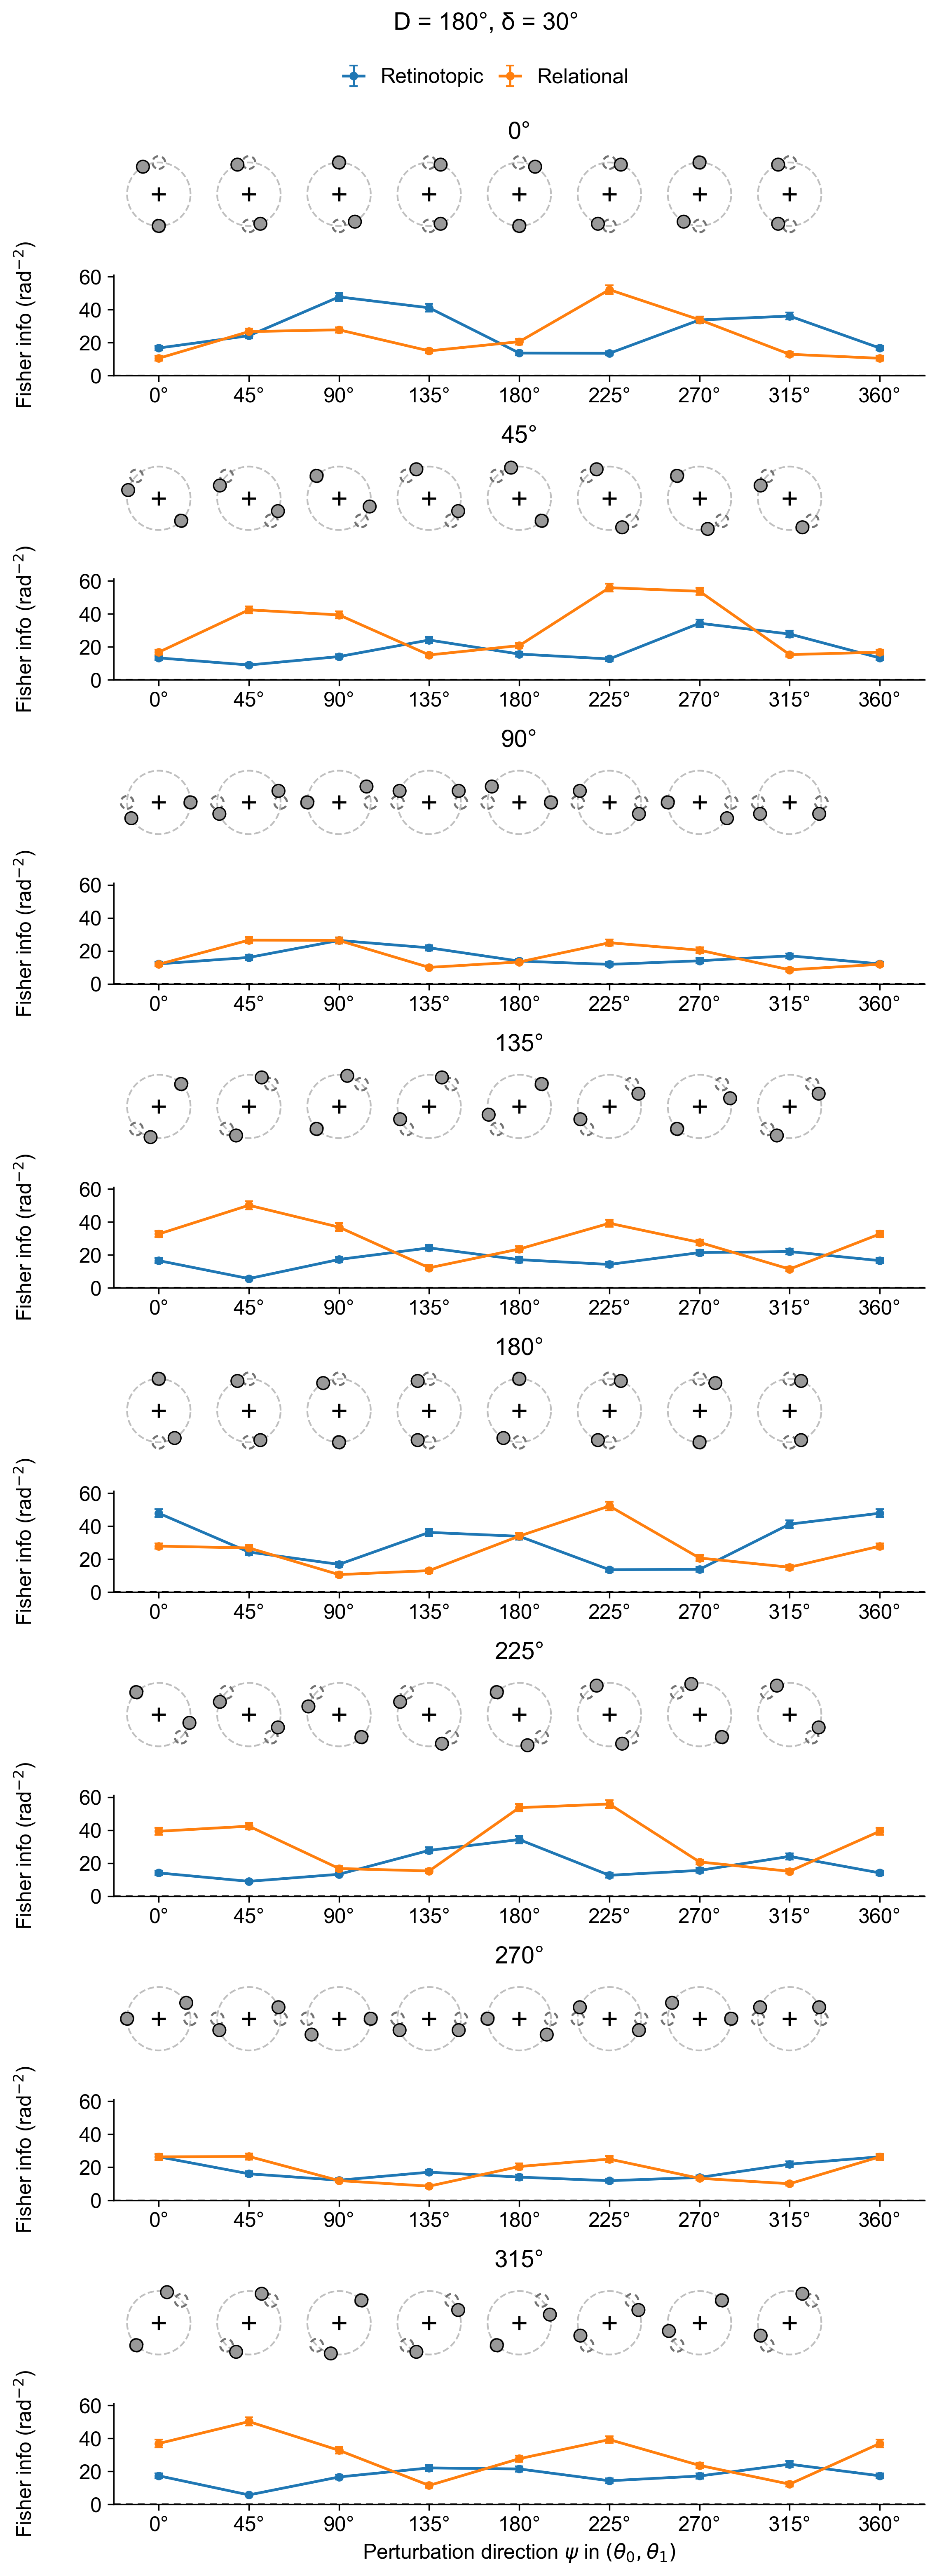

In [39]:
rows = [m for m in ORIENTATIONS_DEG if m in results]
n_rows = int(np.ceil(len(rows) / N_COLS))
# The data range: fixed for accuracy, shared across panels for Fisher information.
if METRIC == 'decoding':
    lo, hi, ref = BAR_YLIM[0], BAR_YLIM[1], 0.5           # ref: the chance line
else:
    vals = np.concatenate([[d['value'] - d['value_sem'], d['value'] + d['value_sem']]
                           for d in (results[m] for m in rows)], axis=None)
    lo, hi, ref = min(0.0, vals.min()), vals.max() * 1.05, 0.0
y_top = hi + INSET_HEADROOM * (hi - lo)
ticks = [t for t in plt.MaxNLocator(4).tick_values(lo, hi) if lo <= t <= hi]

fig, axes = plt.subplots(n_rows, N_COLS, figsize=(N_COLS * PANEL_SIZE[0], n_rows * PANEL_SIZE[1]),
                         squeeze=False, sharey=True)
pops = list(REAL_LABELS)
for k, m in enumerate(rows):
    ax = axes.flat[k]
    stims = STIMULI_DEG[m]
    dec = results[m]
    # Accuracy against perturbation direction psi. psi is an angle, so the 0° point is repeated
    # at 360° to close the loop.
    psi = np.r_[PERTURB_DIRS_DEG, 360.0]
    for pop, color in zip(pops, REAL_COLORS):
        sub = dec[dec['population'] == pop].set_index('pair')
        names = [f'A vs {STIM_LABELS[b]}' for a, b in PAIRS]
        acc = np.array([sub.loc[n, 'value'] for n in names])
        sem = np.array([sub.loc[n, 'value_sem'] for n in names])
        ax.errorbar(psi, np.r_[acc, acc[0]], yerr=np.r_[sem, sem[0]], color=color,
                    marker='o', ms=LINE_MARKER_SIZE, lw=1.6, capsize=2.5, elinewidth=1.2,
                    label=REAL_LABELS[pop], zorder=3)
    ax.axhline(ref, color='k', lw=1.0, ls=(0, (4, 3)), zorder=7)
    ax.set_xticks(np.arange(0, 361, 45))
    ax.set_xticklabels([f'{t}°' for t in range(0, 361, 45)])
    if k == len(rows) - 1:
        ax.set_xlabel(r'Perturbation direction $\psi$ in $(\theta_0, \theta_1)$')
    ax.set_xlim(-22.5, 382.5)
    ax.set_ylim(lo, y_top)
    ax.set_yticks(ticks)
    ax.spines['left'].set_bounds(lo, hi)              # the axis stops where the data does
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title(f'{m}°', fontsize=14)
    if k % N_COLS == 0:
        ax.set_ylabel(METRIC_LABEL)
    # One inset per bar group, centred over it: the stimulus that group compares against A.
    x0, x1 = ax.get_xlim()
    gw = 0.95 * 45.0 / (x1 - x0)                       # one direction's width, in axes fractions
    for xi, (a, b) in zip(PERTURB_DIRS_DEG, PAIRS):
        cx = (xi - x0) / (x1 - x0)
        ins = ax.inset_axes([cx - gw / 2, INSET_Y, gw, INSET_SIZE])
        draw_stimulus(ins, stims[b], ref_deg=stims[a])
for ax in axes.flat[len(rows):]:
    ax.set_visible(False)
# Title, then legend, then the panels, each in its own band at the top.
fig.tight_layout(rect=(0, 0, 1, 1 - 0.75 / fig.get_figheight()))
fig.suptitle(f'D = {SEPARATION_DEG:g}°, δ = {PERTURB_DEG:g}°', fontsize=14,
             y=1 - 0.02 / fig.get_figheight(), va='top')
# The y labels, centred on the accuracy range rather than the whole axis (which runs up into the
# insets), a fixed distance left of the spine so they clear the tick labels at any panel width.
for ax in axes[:, 0]:
    w_in = ax.get_position().width * fig.get_figwidth()
    ax.yaxis.set_label_coords(-0.62 / w_in, 0.5 * (hi - lo) / (y_top - lo))
fig.legend(*axes.flat[0].get_legend_handles_labels(), ncol=2, loc='upper center',
           bbox_to_anchor=(0.5, 1 - 0.32 / fig.get_figheight()), fontsize=12,
           handlelength=1.0, columnspacing=0.8, frameon=False)
plt.show()